In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_style("whitegrid")

In [2]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/healthcare_dataset.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (55500, 15)


,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


In [3]:
print(df.columns.tolist())

['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition', 'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider', 'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date', 'Medication', 'Test Results']


In [4]:
print(df.isnull().sum())

Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
dtype: int64


In [5]:
df["Date of Admission"] = pd.to_datetime(
    df["Date of Admission"],
    errors="coerce"
)

print(df["Date of Admission"].head())

0   2024-01-31
1   2019-08-20
2   2022-09-22
3   2020-11-18
4   2022-09-19
Name: Date of Admission, dtype: datetime64[ns]


In [6]:
df["Discharge Date"] = pd.to_datetime(
    df["Discharge Date"],
    errors="coerce"
)

df["Stay Duration"] = (
    df["Discharge Date"] - df["Date of Admission"]
).dt.days

df[["Date of Admission", "Discharge Date", "Stay Duration"]].head()

,Date of Admission,Discharge Date,Stay Duration
0,2024-01-31,2024-02-02,2
1,2019-08-20,2019-08-26,6
2,2022-09-22,2022-10-07,15
3,2020-11-18,2020-12-18,30
4,2022-09-19,2022-10-09,20


In [7]:

df["Billing Amount"] = pd.to_numeric(
    df["Billing Amount"],
    errors="coerce"
)

df["Billing Amount"].describe()

,Billing Amount
count,55500.000000
mean,25539.316097
std,14211.454431
min,-2008.492140
25%,13241.224652
50%,25538.069376
75%,37820.508436
max,52764.276736


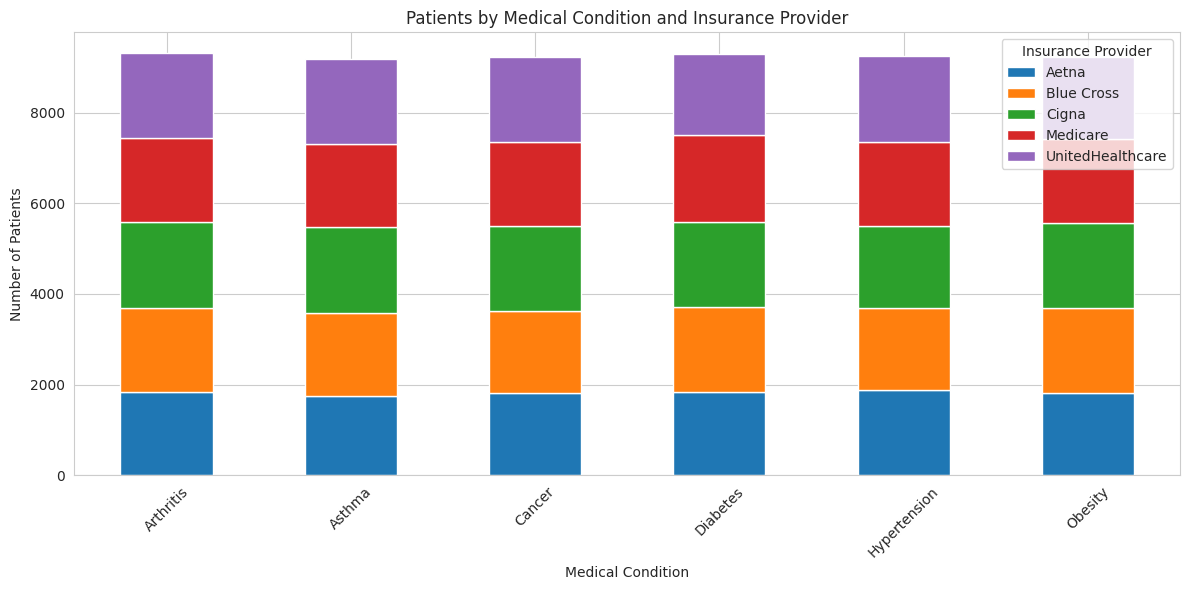

In [8]:

stacked_data = pd.crosstab(
    df["Medical Condition"],
    df["Insurance Provider"]
)

stacked_data.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Patients by Medical Condition and Insurance Provider")
plt.xlabel("Medical Condition")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)
plt.legend(title="Insurance Provider")
plt.tight_layout()
plt.show()

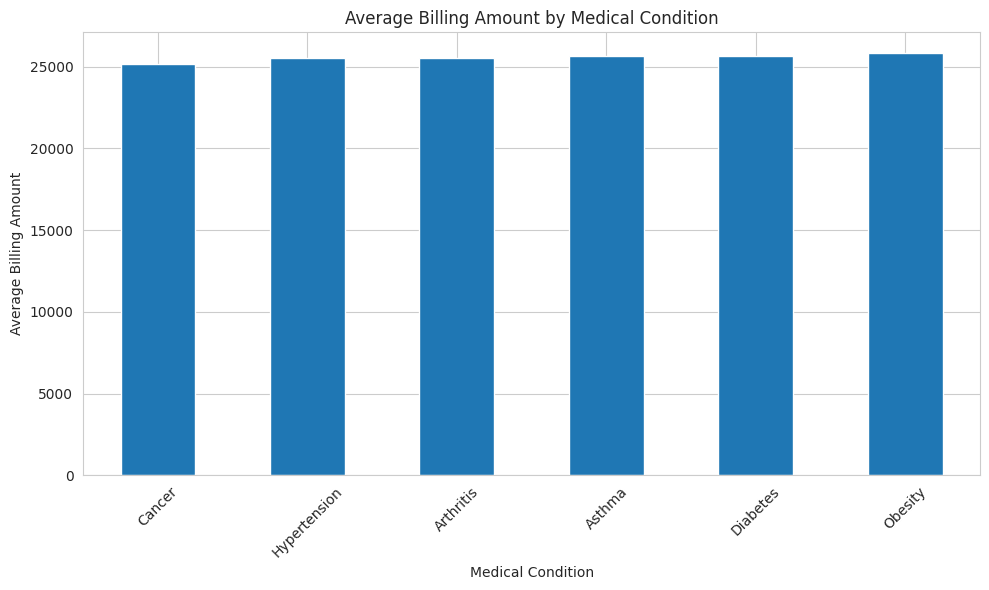

In [9]:
avg_billing = df.groupby(
    "Medical Condition"
)["Billing Amount"].mean().sort_values()

plt.figure(figsize=(10, 6))

avg_billing.plot(kind="bar")

plt.title("Average Billing Amount by Medical Condition")
plt.xlabel("Medical Condition")
plt.ylabel("Average Billing Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

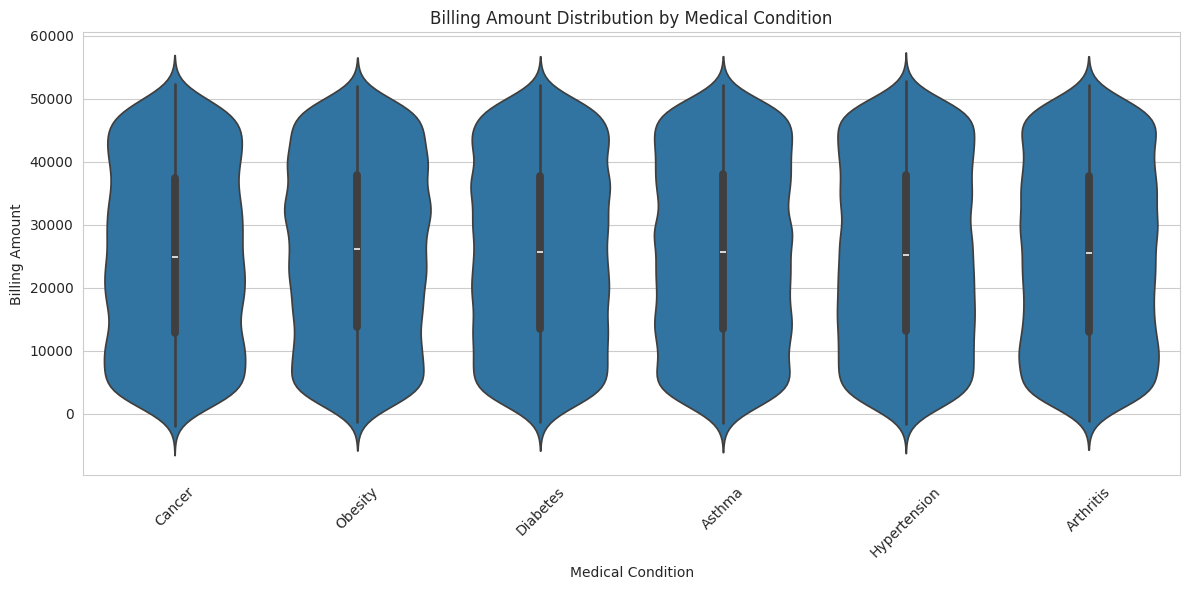

In [10]:

plt.figure(figsize=(12, 6))

sns.violinplot(
    data=df,
    x="Medical Condition",
    y="Billing Amount"
)

plt.title("Billing Amount Distribution by Medical Condition")
plt.xlabel("Medical Condition")
plt.ylabel("Billing Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

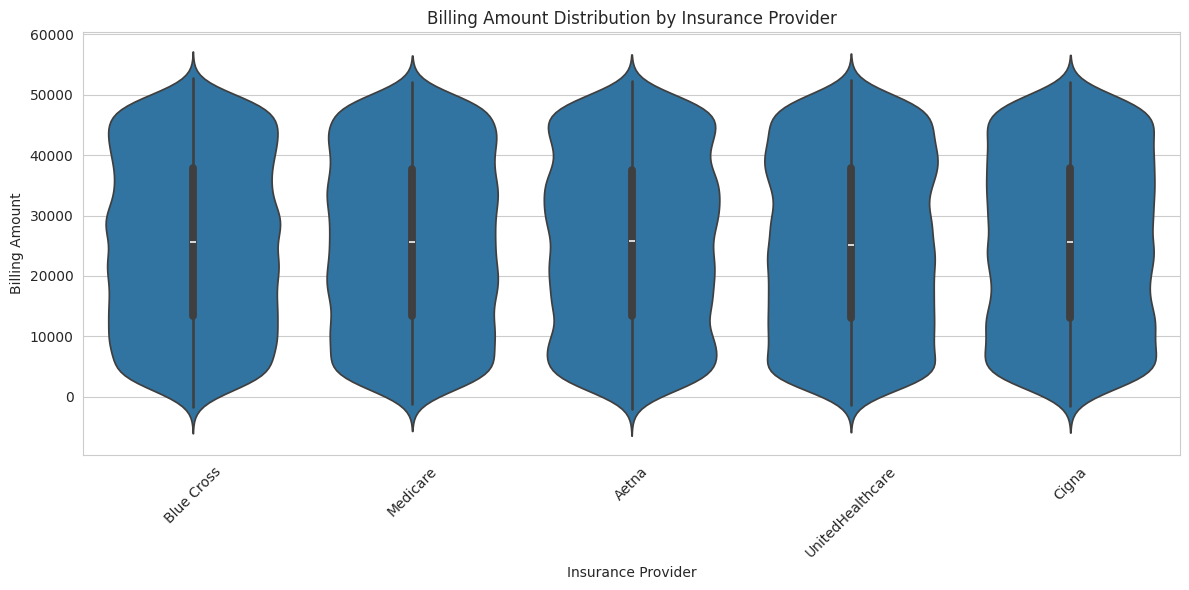

In [11]:
plt.figure(figsize=(12, 6))

sns.violinplot(
    data=df,
    x="Insurance Provider",
    y="Billing Amount"
)

plt.title("Billing Amount Distribution by Insurance Provider")
plt.xlabel("Insurance Provider")
plt.ylabel("Billing Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
monthly_admissions = (
    df.set_index("Date of Admission")
      .resample("ME")
      .size()
)

print(monthly_admissions.head())

Date of Admission
2019-05-31     686
2019-06-30     907
2019-07-31     957
2019-08-31    1001
2019-09-30     936
Freq: ME, dtype: int64


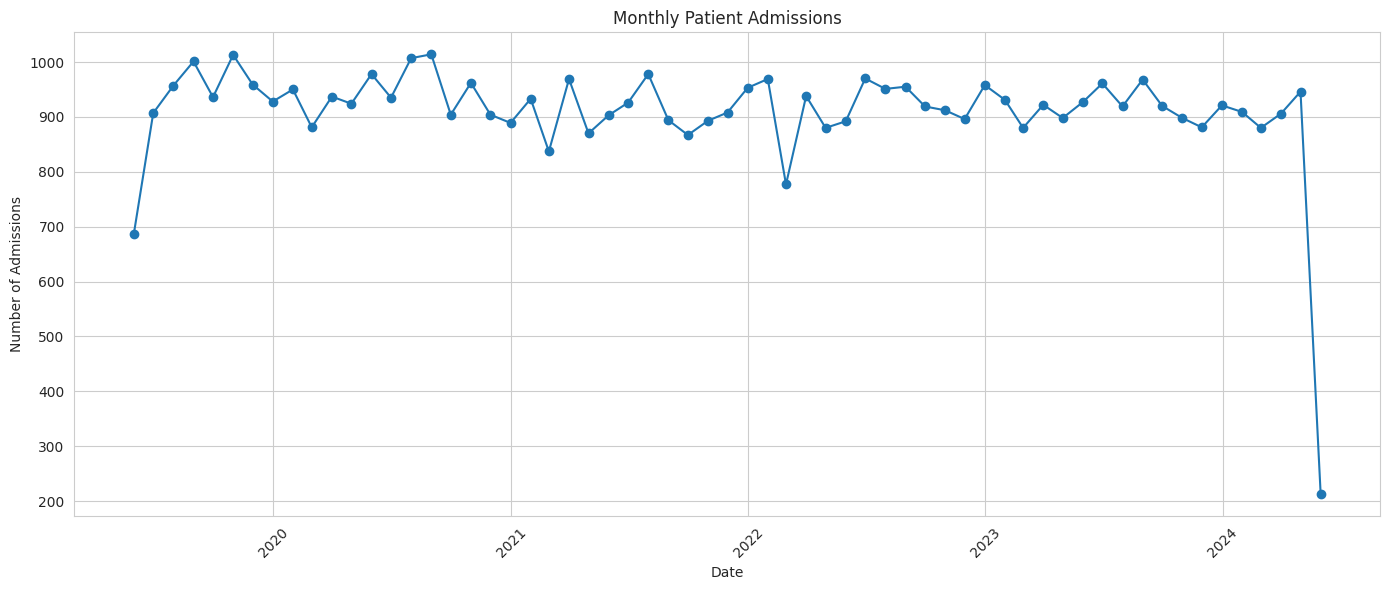

In [13]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_admissions.index,
    monthly_admissions.values,
    marker="o"
)

plt.title("Monthly Patient Admissions")
plt.xlabel("Date")
plt.ylabel("Number of Admissions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
monthly_admissions = monthly_admissions.sort_values(
    ascending=False
)

print("Months with highest patient admissions:")
print(monthly_admissions.head(10))

Months with highest patient admissions:
Date of Admission
2020-08-31    1014
2019-10-31    1013
2020-07-31    1007
2019-08-31    1001
2020-05-31     978
2021-07-31     978
2022-06-30     970
2022-01-31     969
2021-03-31     969
2023-08-31     968
dtype: int64


In [15]:
correlation_data = df[
    ["Age", "Stay Duration", "Billing Amount"]
].copy()

correlation_data.head()

,Age,Stay Duration,Billing Amount
0,30,2,18856.281306
1,62,6,33643.327287
2,76,15,27955.096079
3,28,30,37909.782410
4,43,20,14238.317814


In [16]:
correlation_matrix = correlation_data.corr()

print(correlation_matrix)

                     Age  Stay Duration  Billing Amount
Age             1.000000       0.008220       -0.003832
Stay Duration   0.008220       1.000000       -0.005602
Billing Amount -0.003832      -0.005602        1.000000


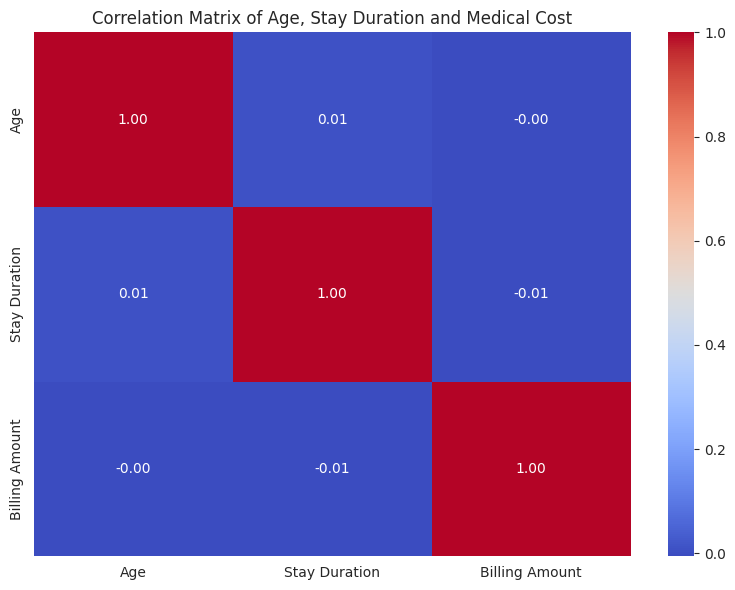

In [19]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Age, Stay Duration and Medical Cost")
plt.tight_layout()
plt.show()

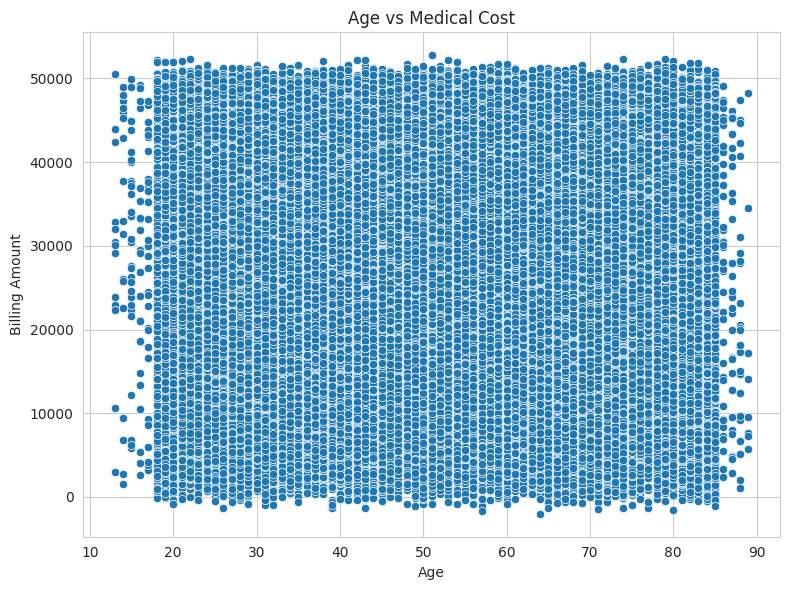

In [20]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="Age",
    y="Billing Amount"
)

plt.title("Age vs Medical Cost")
plt.xlabel("Age")
plt.ylabel("Billing Amount")
plt.tight_layout()
plt.show()

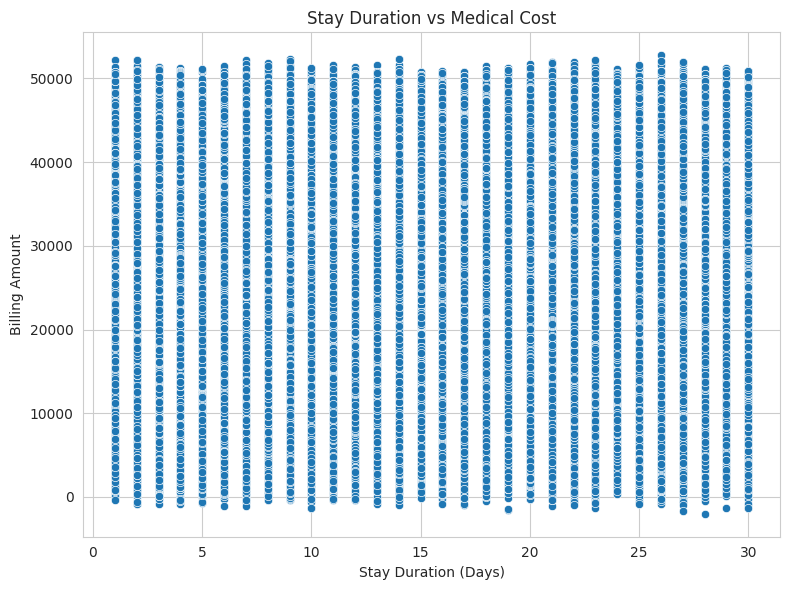

In [21]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="Stay Duration",
    y="Billing Amount"
)

plt.title("Stay Duration vs Medical Cost")
plt.xlabel("Stay Duration (Days)")
plt.ylabel("Billing Amount")
plt.tight_layout()
plt.show()

In [22]:
insurance_cost = df.groupby(
    "Insurance Provider"
)["Billing Amount"].mean().sort_values()

print(insurance_cost)

Insurance Provider
UnitedHealthcare    25389.172390
Cigna               25525.766314
Aetna               25553.294506
Blue Cross          25613.011503
Medicare            25615.990508
Name: Billing Amount, dtype: float64


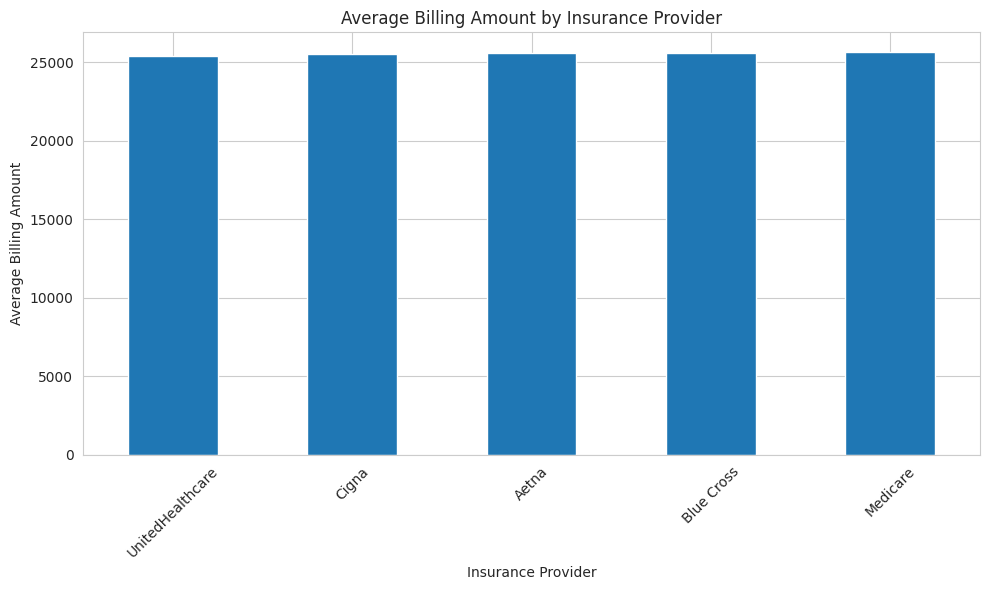

In [23]:
plt.figure(figsize=(10, 6))

insurance_cost.plot(kind="bar")

plt.title("Average Billing Amount by Insurance Provider")
plt.xlabel("Insurance Provider")
plt.ylabel("Average Billing Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [24]:
total_patients = len(df)

average_cost = df["Billing Amount"].mean()

average_stay = df["Stay Duration"].mean()

highest_condition = (
    df.groupby("Medical Condition")["Billing Amount"]
      .mean()
      .idxmax()
)

highest_insurance = (
    df.groupby("Insurance Provider")["Billing Amount"]
      .mean()
      .idxmax()
)

print("========== EXECUTIVE SUMMARY ==========")
print()
print("Total Patients:", total_patients)
print("Average Medical Cost:", round(average_cost, 2))
print("Average Stay Duration:", round(average_stay, 2), "days")
print("Condition with Highest Average Cost:", highest_condition)
print("Insurance Provider with Highest Average Cost:", highest_insurance)

========== EXECUTIVE SUMMARY ==========

Total Patients: 55500
Average Medical Cost: 25539.32
Average Stay Duration: 15.51 days
Condition with Highest Average Cost: Obesity
Insurance Provider with Highest Average Cost: Medicare


In [25]:
print("========== HEALTHCARE MANAGEMENT RECOMMENDATIONS ==========")
print()

print("1. Monitor medical conditions with higher average billing amounts.")
print("2. Analyze long hospital stays to identify possible cost-control opportunities.")
print("3. Use admission trends to improve staff and bed allocation during high-demand periods.")
print("4. Compare insurance-provider billing patterns for better financial planning.")
print("5. Monitor unusual billing amounts to identify possible cost variations.")
print("6. Use patient age and stay-duration patterns to support resource planning.")

========== HEALTHCARE MANAGEMENT RECOMMENDATIONS ==========

1. Monitor medical conditions with higher average billing amounts.
2. Analyze long hospital stays to identify possible cost-control opportunities.
3. Use admission trends to improve staff and bed allocation during high-demand periods.
4. Compare insurance-provider billing patterns for better financial planning.
5. Monitor unusual billing amounts to identify possible cost variations.
6. Use patient age and stay-duration patterns to support resource planning.


In [26]:
print("Healthcare Data Visualization, Cost Relationship & Policy Insights")
print("---------------------------------------------------------------")
print("✓ Stacked bar chart created")
print("✓ Violin plots created")
print("✓ Monthly admission trend analyzed")
print("✓ Correlation matrix created")
print("✓ Medical cost relationships analyzed")
print("✓ Executive summary generated")
print("✓ Healthcare management recommendations generated")

Healthcare Data Visualization, Cost Relationship & Policy Insights
---------------------------------------------------------------
✓ Stacked bar chart created
✓ Violin plots created
✓ Monthly admission trend analyzed
✓ Correlation matrix created
✓ Medical cost relationships analyzed
✓ Executive summary generated
✓ Healthcare management recommendations generated
